# Single-trial rat ABR: progress report notebook
Amelia Schaefer, MCB 493. Functions live in `abr_tools.py` (same folder) and are imported (Lecture 15).
Run with **Kernel -> Restart Kernel and Run All Cells**.

Data: Bieszczad & Gungor Aydin (2026), Zenodo doi:10.5281/zenodo.23066665 (CC-BY 4.0).

## 1. Settings

In [1]:
import os
import sys
from pathlib import Path

PROJECT_FOLDER = Path("/Users/ameliaschaefer/Desktop/abr_pipeline")          # folder with this notebook and abr_tools.py
os.chdir(PROJECT_FOLDER)
sys.path.insert(0, str(PROJECT_FOLDER))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

import abr_tools as at

DATA_FOLDER = PROJECT_FOLDER / "Bieszczad et al., Full waveform ABR data"
OUT_FOLDER = PROJECT_FOLDER / "results"
(OUT_FOLDER / "figures").mkdir(parents=True, exist_ok=True)

FS = 195_200                 # Hz (Zenodo record; not stored in the files)
N_SAMPLES = 1_952            # samples per trial = 10 ms
LOWCUT, HIGHCUT, ORDER, PAD_MS = 300.0, 3000.0, 4, 3.0
DOWNSAMPLE = 10              # -> 19,520 Hz after the 3 kHz low-pass
REJECT_K = 5.0               # peak-to-peak > median + 5 MAD
PEAK_SEARCH_MS, MIN_PEAK_SIZE, WINDOW_HALF_MS, TROUGH_SEARCH_MS = (1.0, 5.5), 0.10, 0.25, 0.6

FREQS = np.arange(500, 3001, 100)   # Hz, Morlet frequencies
N_CYCLES = 3                        # Morlet, 3 cycles (time smear ~ n_cycles/f)
ITPC_BAND = (1000, 2000)            # Hz, band for the summary ITPC
SUBAVG, N_BOOT, JITTER_SEED = 32, 1000, 11   # jitter: sub-averages of 32 trials
N_PERM, N_PERM_JITTER = 1000, 500
SEED = 0

PRE_C, POST_C = "#3a6ea5", "#c2552f"   # validated pair (dataviz palette check: all pass)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

print("abr_tools loaded from the project folder:", Path(at.__file__).parent == PROJECT_FOLDER)
print("data folder found:", DATA_FOLDER.is_dir())

abr_tools loaded from the project folder: True
data folder found: True


## 2. Files: find, de-duplicate, label

In [2]:
missing = at.missing_files(DATA_FOLDER)
if missing:
    print(f"{len(missing)} of 26 data files are missing from {DATA_FOLDER.name}:")
    for f in missing:
        print("   ", f)
    raise FileNotFoundError("Data incomplete: re-unzip 'Full waveform ABR data.zip' into the data folder (see list above).")
print("all 26 data files present")

files, dups = at.list_unique_files(DATA_FOLDER)
for d, same in dups:
    print(f"duplicate skipped: {d}  (same as {same})")
names = [str(p.relative_to(DATA_FOLDER)) for p in files]
info = {n: at.describe_file(n) for n in names}
print(f"{len(files)} unique sessions")
assert len(files) == 21, f"expected 21 unique sessions, found {len(files)}"
pd.DataFrame([{"file": n, **info[n]} for n in names])

all 26 data files present


duplicate skipped: Figure 4/APP_33_ss_pretraining.csv  (same as Figure 3/APP_33_pretraining_ss.csv)
duplicate skipped: Figure 4/APP_53_hh_pretraining.csv  (same as Figure 3/APP_53_pretraining_hh.csv)
duplicate skipped: Supplemental Figure 1/APP_105_hh.csv  (same as Figure 2/APP_105-hh.csv)
duplicate skipped: test_data/testsubject_hh.csv  (same as Figure 3/APP_50_pretraining_hh.csv)
duplicate skipped: test_data/testsubject_ss.csv  (same as Figure 3/APP_35_pretraining_ss.csv)
21 unique sessions


,file,folder,rat,genotype,condition,sex,cohort
0,Figure 2/APP_01_hh.csv,Figure 2,APP_01,AppH,untrained,,aged
1,Figure 2/APP_04_ss.csv,Figure 2,APP_04,AppS,untrained,,aged
2,Figure 2/APP_05_hh.csv,Figure 2,APP_05,AppH,untrained,,aged
3,Figure 2/APP_06_ss.csv,Figure 2,APP_06,AppS,untrained,,aged
4,Figure 2/APP_102_ss.csv,Figure 2,APP_102,AppS,untrained,,aged
5,Figure 2/APP_105-hh.csv,Figure 2,APP_105,AppH,untrained,,aged
6,Figure 3/APP_33_pretraining_ss.csv,Figure 3,APP_33,AppS,pre,,young
7,Figure 3/APP_35_pretraining_ss.csv,Figure 3,APP_35,AppS,pre,,young
8,Figure 3/APP_43_pretraining_ss.csv,Figure 3,APP_43,AppS,pre,,young
9,Figure 3/APP_44_pretraining_ss.csv,Figure 3,APP_44,AppS,pre,,young


## 3. Load and preprocess every session, with sanity checks (Lecture 15)

In [3]:
rng = np.random.default_rng(SEED)
clean, summary = {}, []
for path, name in zip(files, names):
    raw, layout, units = at.load_trials(path, N_SAMPLES)
    assert raw.shape == (514, N_SAMPLES), f"{name}: unexpected shape {raw.shape}"
    x, fs, keep, thr = at.preprocess(raw, FS, LOWCUT, HIGHCUT, ORDER, PAD_MS, DOWNSAMPLE, REJECT_K)
    clean[name] = x
    summary.append({"file": name, **info[name], "units": units, "n_trials": len(raw),
                    "n_rejected": int((~keep).sum()), "single_trial_sd_uV": x.std(),
                    "noise_of_average_uV": at.noise_of_average(x, rng)})
summary = pd.DataFrame(summary)
# plausible range: ABR single trials here are sub-microvolt after filtering (not EEG's tens of uV)
assert summary.single_trial_sd_uV.between(0.1, 5).all(), "single-trial SD outside 0.1-5 uV"
print(f"single-trial SD after filtering: {summary.single_trial_sd_uV.min():.2f}-"
      f"{summary.single_trial_sd_uV.max():.2f} uV")
print(f"fs after downsampling: {fs:.0f} Hz")

by_cond = summary.groupby("condition")[["n_trials", "n_rejected"]].sum()
by_cond["pct_rejected"] = (100 * by_cond.n_rejected / by_cond.n_trials).round(1)
print(f"rejected {summary.n_rejected.sum()} of {summary.n_trials.sum()} trials overall")
by_cond   # Lecture 10: rejection must be even across conditions

single-trial SD after filtering: 0.39-0.59 uV
fs after downsampling: 19520 Hz
rejected 47 of 10794 trials overall


,n_trials,n_rejected,pct_rejected
condition,,,
post,1028,1,0.1
post_6weeks,514,0,0.0
post_9months,514,0,0.0
pre,3084,8,0.3
untrained,5654,38,0.7


### Sanity check: noise of the average falls as 1/sqrt(n) (Lecture 15)

In [4]:
slopes = []
for name, x in clean.items():
    ns, noise, slope = at.noise_vs_n(x, [16, 32, 64, 128, 256, 500], rng)
    slopes.append(slope)
print(f"log-log slope of noise vs. n: median {np.median(slopes):.3f} "
      f"(range {min(slopes):.3f} to {max(slopes):.3f}); expected -0.5")
assert abs(np.median(slopes) + 0.5) < 0.05

log-log slope of noise vs. n: median -0.502 (range -0.518 to -0.493); expected -0.5


## 4. Grand average and fixed peak windows (Lecture 10: windows chosen before comparing)

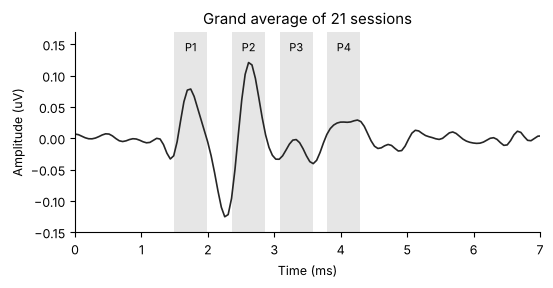

,peak,center_ms,lo_ms,hi_ms
0,P1,1.742,1.492,1.992
1,P2,2.613,2.363,2.863
2,P3,3.330,3.080,3.580
3,P4,4.047,3.797,4.297


In [5]:
grand = np.mean([x.mean(axis=0) for x in clean.values()], axis=0)
t = np.arange(len(grand)) / fs * 1000
windows = at.find_peak_windows(grand, fs, PEAK_SEARCH_MS, MIN_PEAK_SIZE, WINDOW_HALF_MS)
assert all(1.0 < w["center_ms"] < 6.0 for w in windows), "ABR peaks should fall 1-6 ms after onset"

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.plot(t, grand, color="0.15", lw=1.2)
for w in windows:
    ax.axvspan(w["lo_ms"], w["hi_ms"], color="0.9", lw=0)
    ax.text(w["center_ms"], grand.max() * 1.15, w["peak"], ha="center", fontsize=8)
ax.set(xlim=(0, 7), ylim=(grand.min() * 1.2, grand.max() * 1.4), xlabel="Time (ms)",
       ylabel="Amplitude (uV)", title=f"Grand average of {len(clean)} sessions")
plt.show()
pd.DataFrame(windows)

## 5. Peak measures for every session

In [6]:
rows = []
for name, x in clean.items():
    for pk in at.measure_peaks(x.mean(axis=0), fs, windows, TROUGH_SEARCH_MS):
        rows.append({"file": name, "rat": info[name]["rat"], "genotype": info[name]["genotype"],
                     "condition": info[name]["condition"], **pk})
peaks = pd.DataFrame(rows)
peaks.pivot(index="file", columns="peak", values="trough_to_peak_uV").round(3)

peak,P1,P2,P3,P4
file,,,,
Figure 2/APP_01_hh.csv,0.079,0.161,0.131,0.094
Figure 2/APP_04_ss.csv,0.121,0.384,0.112,0.138
Figure 2/APP_05_hh.csv,0.094,0.181,0.070,0.146
Figure 2/APP_06_ss.csv,0.168,0.449,0.135,0.141
Figure 2/APP_102_ss.csv,0.150,0.394,0.098,0.115
Figure 2/APP_105-hh.csv,0.110,0.253,0.126,0.117
Figure 3/APP_33_pretraining_ss.csv,0.115,0.449,0.072,0.109
Figure 3/APP_35_pretraining_ss.csv,0.141,0.366,0.086,0.056
Figure 3/APP_43_pretraining_ss.csv,0.210,0.712,0.160,0.230


## 6. Trained rats: pre vs. post (equal trial counts)

In [7]:
def session(rat, cond):
    return next(clean[n] for n in names if info[n]["rat"] == rat and info[n]["condition"] == cond)

trained = sorted({info[n]["rat"] for n in names if info[n]["condition"] == "post"})
pairs = {rat: at.equal_n(session(rat, "pre"), session(rat, "post"), rng) for rat in trained}
for rat, (a, b) in pairs.items():
    print(f"{rat} ({next(info[n]['genotype'] for n in names if info[n]['rat'] == rat)}): "
          f"{len(a)} trials per session")

peaks[peaks.rat.isin(trained) & peaks.condition.isin(["pre", "post"])].pivot_table(
    index=["rat", "peak"], columns="condition",
    values=["trough_to_peak_uV", "peak_latency_ms"]).round(3)

APP_33 (AppS): 513 trials per session
APP_53 (AppH): 514 trials per session


peak_latency_ms        trough_to_peak_uV       
condition              post    pre              post    pre
rat    peak                                                
APP_33 P1             1.639  1.588             0.219  0.115
       P2             2.459  2.408             0.555  0.449
       P3             3.125  3.586             0.191  0.072
       P4             4.047  3.996             0.166  0.109
APP_53 P1             1.742  1.793             0.164  0.130
       P2             2.664  2.715             0.640  0.468
       P3             3.227  3.381             0.257  0.287
       P4             3.996  4.252             0.102  0.118

## 7. Prediction 1: ITPC (Lecture 7 Morlet phase; Lecture 14 mean vector length)

In [8]:
n_times = next(iter(clean.values())).shape[1]
valid, summary_mask = at.itpc_masks(n_times, fs, FREQS, N_CYCLES, windows, ITPC_BAND)
itpc_stat = lambda u: at.itpc_summary(u, summary_mask)

phases, itpc_rows = {}, []
for rat, (a, b) in pairs.items():
    ua, ub = at.phase_vectors(a, fs, FREQS, N_CYCLES), at.phase_vectors(b, fs, FREQS, N_CYCLES)
    phases[rat] = (ua, ub)
    obs, p, _ = at.permutation_p(ua, ub, itpc_stat, N_PERM, rng)
    itpc_rows.append({"rat": rat, "itpc_pre": itpc_stat(ua), "itpc_post": itpc_stat(ub),
                      "change": obs, "p": p, "split_half_drift": at.split_half_diff(ua, itpc_stat)})
itpc_results = pd.DataFrame(itpc_rows)
itpc_results.round(4)

,rat,itpc_pre,itpc_post,change,p,split_half_drift
0,APP_33,0.2241,0.3128,0.0887,0.0010,-0.0142
1,APP_53,0.3660,0.3580,-0.0081,0.5375,-0.0055


## 8. Prediction 2: latency jitter (Lecture 10), fixed seed so runs agree

In [9]:
jit_stat = lambda x: at.jitter(x, fs, windows, SUBAVG, N_BOOT, JITTER_SEED).mean()
jit_rows, jit_by_peak = [], []
for rat, (a, b) in pairs.items():
    ja = at.jitter(a, fs, windows, SUBAVG, N_BOOT, JITTER_SEED)
    jb = at.jitter(b, fs, windows, SUBAVG, N_BOOT, JITTER_SEED)
    for w, x0, x1 in zip(windows, ja, jb):
        jit_by_peak.append({"rat": rat, "peak": w["peak"], "jitter_pre_ms": x0, "jitter_post_ms": x1})
    obs, p, _ = at.permutation_p(a, b, jit_stat, N_PERM_JITTER, rng)
    jit_rows.append({"rat": rat, "jitter_pre_ms": ja.mean(), "jitter_post_ms": jb.mean(),
                     "change_ms": obs, "p": p, "split_half_drift_ms": at.split_half_diff(a, jit_stat)})
jitter_results = pd.DataFrame(jit_rows)
print(pd.DataFrame(jit_by_peak).round(3).to_string(index=False))
jitter_results.round(4)

   rat peak  jitter_pre_ms  jitter_post_ms
APP_33   P1          0.127           0.079
APP_33   P2          0.068           0.073
APP_33   P3          0.185           0.111
APP_33   P4          0.119           0.119
APP_53   P1          0.112           0.083
APP_53   P2          0.047           0.034
APP_53   P3          0.065           0.126
APP_53   P4          0.117           0.134


,rat,jitter_pre_ms,jitter_post_ms,change_ms,p,split_half_drift_ms
0,APP_33,0.1250,0.0955,-0.0295,0.0020,-0.0059
1,APP_53,0.0853,0.0944,0.0091,0.2096,0.0020


### Stability check: jitter with three different seeds (should agree)

In [10]:
pd.DataFrame([{"rat": rat, "seed": s,
               "pre": at.jitter(a, fs, windows, SUBAVG, N_BOOT, s).mean(),
               "post": at.jitter(b, fs, windows, SUBAVG, N_BOOT, s).mean()}
              for rat, (a, b) in pairs.items() for s in (11, 22, 33)]).round(4)

,rat,seed,pre,post
0,APP_33,11,0.1250,0.0955
1,APP_33,22,0.1230,0.0965
2,APP_33,33,0.1251,0.0960
3,APP_53,11,0.0853,0.0944
4,APP_53,22,0.0837,0.0907
5,APP_53,33,0.0865,0.0944


## 9. Genotype comparison: 12 App rats, one session each, exact permutation on animal labels

In [11]:
geno = pd.DataFrame([{"file": n, "rat": info[n]["rat"], "genotype": info[n]["genotype"],
                      "cohort": info[n]["cohort"]}
                     for n in names if info[n]["genotype"] in ("AppS", "AppH")
                     and info[n]["condition"] in ("untrained", "pre")]).drop_duplicates("rat").reset_index(drop=True)
n_min = min(len(clean[f]) for f in geno.file)
g_trials = {r.rat: clean[r.file][np.sort(rng.choice(len(clean[r.file]), n_min, replace=False))]
            for r in geno.itertuples()}
p2 = peaks[peaks.peak == "P2"].set_index("file")
geno["itpc"] = [itpc_stat(at.phase_vectors(g_trials[r], fs, FREQS, N_CYCLES)) for r in geno.rat]
geno["jitter_ms"] = [jit_stat(g_trials[r]) for r in geno.rat]
geno["P2_trough_to_peak_uV"] = [p2.loc[f, "trough_to_peak_uV"] for f in geno.file]
print(pd.crosstab(geno.cohort, geno.genotype))

measures = ["itpc", "jitter_ms", "P2_trough_to_peak_uV"]
geno_tests = []
for col in measures:
    obs, p, n_lab = at.exact_genotype_test(geno, col)
    geno_tests.append({"measure": col, "AppS_mean": geno[geno.genotype == "AppS"][col].mean(),
                       "AppH_mean": geno[geno.genotype == "AppH"][col].mean(),
                       "diff_S_minus_H": obs, "exact_p": p,
                       "bonferroni_p": min(1.0, p * len(measures)), "n_relabelings": n_lab})
geno_tests = pd.DataFrame(geno_tests)
print(geno.drop(columns="file").round(3).to_string(index=False))
geno_tests.round(4)

genotype  AppH  AppS
cohort              
aged         3     3
young        2     4
    rat genotype cohort  itpc  jitter_ms  P2_trough_to_peak_uV
 APP_01     AppH   aged 0.156      0.161                 0.161
 APP_04     AppS   aged 0.207      0.118                 0.384
 APP_05     AppH   aged 0.137      0.130                 0.181
 APP_06     AppS   aged 0.285      0.087                 0.449
APP_102     AppS   aged 0.216      0.122                 0.394
APP_105     AppH   aged 0.140      0.129                 0.253
 APP_33     AppS  young 0.225      0.122                 0.449
 APP_35     AppS  young 0.232      0.124                 0.366
 APP_43     AppS  young 0.414      0.094                 0.712
 APP_44     AppS  young 0.290      0.092                 0.723
 APP_50     AppH  young 0.365      0.091                 0.502
 APP_53     AppH  young 0.366      0.084                 0.468


,measure,AppS_mean,AppH_mean,diff_S_minus_H,exact_p,bonferroni_p,n_relabelings
0,itpc,0.2671,0.2330,0.0341,0.4733,1.0,300
1,jitter_ms,0.1084,0.1192,-0.0108,0.3767,1.0,300
2,P2_trough_to_peak_uV,0.4968,0.3131,0.1837,0.0333,0.1,300


## 10. Report figure

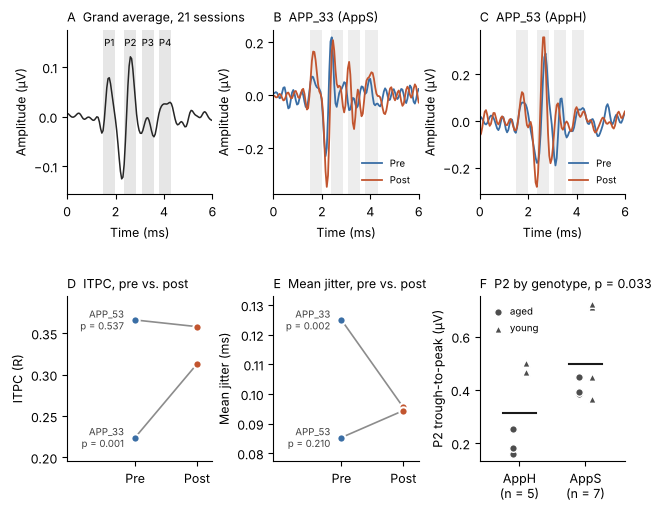

In [12]:
fig = plt.figure(figsize=(7.2, 5.6))
gs = fig.add_gridspec(2, 3, hspace=0.62, wspace=0.42)
rat_geno = dict(zip(geno.rat, geno.genotype))

# A: grand average
ax = fig.add_subplot(gs[0, 0])
ax.plot(t, grand, color="0.15", lw=1.1)
for w in windows:
    ax.axvspan(w["lo_ms"], w["hi_ms"], color="0.9", lw=0)
    ax.text(w["center_ms"], grand.max() * 1.18, w["peak"], ha="center", fontsize=7)
ax.set(xlim=(0, 6), ylim=(grand.min() * 1.25, grand.max() * 1.45), xlabel="Time (ms)",
       ylabel="Amplitude (\u00b5V)")
ax.set_title(f"A  Grand average, {len(clean)} sessions", loc="left", fontsize=9)

# B, C: pre vs post averages
for k, rat in enumerate(trained):
    ax = fig.add_subplot(gs[0, 1 + k])
    for w in windows:
        ax.axvspan(w["lo_ms"], w["hi_ms"], color="0.93", lw=0)
    for x, lab, c in zip(pairs[rat], ["Pre", "Post"], [PRE_C, POST_C]):
        ax.plot(np.arange(x.shape[1]) / fs * 1000, x.mean(axis=0), color=c, lw=1.3, label=lab)
    ax.set(xlim=(0, 6), xlabel="Time (ms)", ylabel="Amplitude (\u00b5V)")
    ax.set_title(f"{'BC'[k]}  {rat} ({rat_geno[rat]})", loc="left", fontsize=9)
    ax.legend(frameon=False, fontsize=7, loc="lower right")

# D, E: ITPC and jitter pre vs post, one line per rat, direct labels
for k, (res, pre_col, post_col, p_col, lab) in enumerate([
        (itpc_results, "itpc_pre", "itpc_post", "p", "ITPC (R)"),
        (jitter_results, "jitter_pre_ms", "jitter_post_ms", "p", "Mean jitter (ms)")]):
    ax = fig.add_subplot(gs[1, k])
    for _, r in res.iterrows():
        ax.plot([0, 1], [r[pre_col], r[post_col]], color="0.55", lw=1.2, zorder=1)
        ax.scatter([0], [r[pre_col]], color=PRE_C, s=36, zorder=2, edgecolor="white", linewidth=1.5)
        ax.scatter([1], [r[post_col]], color=POST_C, s=36, zorder=2, edgecolor="white", linewidth=1.5)
        ax.annotate(f"{r.rat}\np = {r[p_col]:.3f}", (0, r[pre_col]), xytext=(-8, 0),
                    textcoords="offset points", va="center", ha="right", fontsize=7, color="0.25")
    ax.set(xticks=[0, 1], xticklabels=["Pre", "Post"], xlim=(-1.1, 1.25), ylabel=lab)
    ax.margins(y=0.2)
    ax.set_title(f"{'DE'[k]}  {lab.split(' (')[0]}, pre vs. post", loc="left", fontsize=9)

# F: genotype, P2 trough-to-peak, one marker per rat; shape = cohort
ax = fig.add_subplot(gs[1, 2])
for j, g in enumerate(["AppH", "AppS"]):
    sub = geno[geno.genotype == g]
    for cohort, mk, off in [("aged", "o", -0.1), ("young", "^", 0.1)]:
        s = sub[sub.cohort == cohort]
        ax.scatter(np.full(len(s), j + off), s.P2_trough_to_peak_uV, marker=mk, s=30,
                   color="0.3", edgecolor="white", linewidth=1, zorder=2,
                   label=cohort if j == 1 else None)
    ax.plot([j - 0.25, j + 0.25], [sub.P2_trough_to_peak_uV.mean()] * 2, color="0.1", lw=1.5)
p = geno_tests.set_index("measure").loc["P2_trough_to_peak_uV", "exact_p"]
ax.set(xticks=[0, 1], xticklabels=["AppH\n(n = 5)", "AppS\n(n = 7)"], xlim=(-0.6, 1.6),
       ylabel="P2 trough-to-peak (\u00b5V)")
ax.set_title(f"F  P2 by genotype, p = {p:.3f}", loc="left", fontsize=9)
ax.legend(frameon=False, fontsize=7, loc="upper left", handletextpad=0.2)

fig.savefig(OUT_FOLDER / "figures" / "progress_report_figure.png", dpi=300, bbox_inches="tight")
plt.show()

## 11. Save results

In [13]:
summary.to_csv(OUT_FOLDER / "summary.csv", index=False)
peaks.to_csv(OUT_FOLDER / "peaks.csv", index=False)
pd.DataFrame(windows).to_csv(OUT_FOLDER / "peak_windows.csv", index=False)
itpc_results.to_csv(OUT_FOLDER / "itpc_results.csv", index=False)
jitter_results.to_csv(OUT_FOLDER / "jitter_results.csv", index=False)
geno.drop(columns="file").to_csv(OUT_FOLDER / "genotype_per_rat.csv", index=False)
geno_tests.to_csv(OUT_FOLDER / "genotype_tests.csv", index=False)
print("saved")

saved
